Best solution (x): 0.0013648219786815685
Minimum fitness f(x): 1.8627390334922718e-06


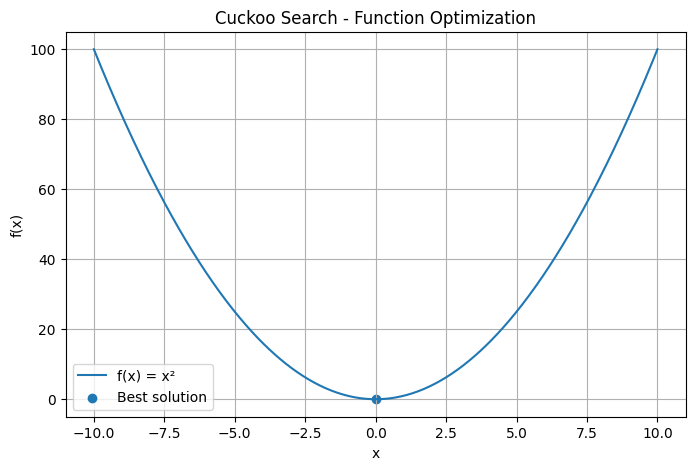

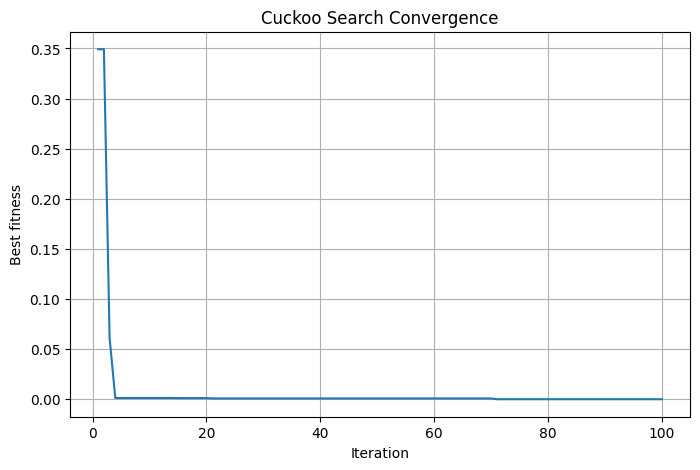

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Objective function
def fitness(x):
    return x**2

# 2. Initialize parameters
N = 25
Pa = 0.25
MAX_ITER = 100
LOWER = -10
UPPER = 10

# 3. Initialize nests randomly
nests = np.random.uniform(LOWER, UPPER, N)
scores = fitness(nests)

# Store the best solution found
best_index = np.argmin(scores)
best = nests[best_index]
best_score = scores[best_index]

history = []

# 4. Main optimization loop
for iteration in range(MAX_ITER):

    # Generate new solutions using a simplified Levy-flight step
    step = np.random.standard_cauchy(N) * 0.01
    new_nests = nests + step * (nests - best)

    # Keep solutions within bounds
    new_nests = np.clip(new_nests, LOWER, UPPER)
    new_scores = fitness(new_nests)

    # 5. Replace nests if new solutions are better
    improved = new_scores < scores
    nests[improved] = new_nests[improved]
    scores[improved] = new_scores[improved]

    # 6. Abandon some nests
    abandon = np.random.rand(N) < Pa
    nests[abandon] = np.random.uniform(
        LOWER, UPPER, np.sum(abandon)
    )
    scores[abandon] = fitness(nests[abandon])

    # 7. Update the best solution found
    index = np.argmin(scores)

    if scores[index] < best_score:
        best = nests[index]
        best_score = scores[index]

    history.append(best_score)

# 8. Display the result
print("Best solution (x):", best)
print("Minimum fitness f(x):", best_score)

# 9. Plot the objective function
x = np.linspace(LOWER, UPPER, 500)

plt.figure(figsize=(8, 5))
plt.plot(x, fitness(x), label="f(x) = x²")
plt.scatter(best, best_score, label="Best solution")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Cuckoo Search - Function Optimization")
plt.legend()
plt.grid(True)
plt.show()

# 10. Plot convergence
plt.figure(figsize=(8, 5))
plt.plot(range(1, MAX_ITER + 1), history)
plt.xlabel("Iteration")
plt.ylabel("Best fitness")
plt.title("Cuckoo Search Convergence")
plt.grid(True)
plt.show()